# Gradient Boosting: 

**Goal:** Predict log price with gradient boosting. Unlike bagging and random forests, which build trees independently and average them, boosting builds trees one after another. Each new tree is trained to correct the errors of the trees before it. The learning rate controls how much each tree contributes.

**Setup:** Same cleaned data, 80/20 split (`random_state=42`), and 5-fold CV as the other notebooks. Categorical features are one-hot encoded, and numeric features pass through unchanged.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load the cleaned data saved from the KNN notebook's cleaning steps
df = pd.read_csv('../data/cardekho_clean.csv')
df['log_price'] = np.log(df['selling_price'])

num_cols = ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
cat_cols = ['brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']
X = df[num_cols + cat_cols]
y = df['log_price']

# Same split and CV as the KNN notebook so results are comparable
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

LUXURY = ['Land Rover', 'Jaguar', 'Mercedes-Benz', 'Audi', 'BMW']

def evaluate(pred_log, name):
    rmse = np.sqrt(mean_squared_error(y_test, pred_log))
    r2 = r2_score(y_test, pred_log)
    mae = mean_absolute_error(np.exp(y_test), np.exp(pred_log))
    print(f"{name}: test RMSE (log) {rmse:.4f} | R2 {r2:.4f} | MAE Rs {mae:,.0f}")
    return {'model': name, 'test_rmse_log': round(rmse, 4), 'test_r2': round(r2, 4), 'test_mae_rs': round(mae)}

def segment_report(pred_log):
    d = pd.DataFrame({
        'actual': np.exp(y_test.values),
        'pred': np.exp(pred_log),
        'brand': X_test['brand'].values,
    })
    d['pct_error'] = np.abs(d['pred'] - d['actual']) / d['actual']
    d['segment'] = pd.qcut(d['actual'], 4, labels=['Q1 cheapest', 'Q2', 'Q3', 'Q4 priciest'])
    return d

def print_segments(pred_log):
    d = segment_report(pred_log)
    print(d.groupby('segment', observed=True)['pct_error'].mean().round(3))
    print(d[d['brand'].isin(LUXURY)].groupby('brand')['pct_error'].agg(['size', 'mean']).round(3))

def original_feature(name):
    # Maps one-hot names like 'cat__brand_Maruti' back to 'brand'
    name = name.split('__', 1)[1]
    for col in cat_cols + num_cols:
        if name == col or name.startswith(col + '_'):
            return col
    return name

print(X_train.shape, X_test.shape)

(12184, 11) (3046, 11)


## 1. Tune the boosting model

The main settings are:
- `n_estimators` is the number of trees. More trees fit the training data more closely.
- `learning_rate` scales each tree's contribution. Smaller values need more trees but often generalize better.
- `max_depth` controls how complex each tree is. Boosting usually uses shallow trees.
- `min_samples_leaf` sets the smallest number of cars allowed in a leaf.

We choose the settings by CV on the training set only.

In [2]:
from sklearn.ensemble import GradientBoostingRegressor

gb_prep = ColumnTransformer(
    [('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)],
    remainder='passthrough'
)
gb_pipe = Pipeline([
    ('prep', gb_prep),
    ('gb', GradientBoostingRegressor(random_state=42)),
])
gb_param_grid = {
    'gb__n_estimators': [300, 600],
    'gb__learning_rate': [0.05, 0.1],
    'gb__max_depth': [3, 5],
    'gb__min_samples_leaf': [5, 20],
}
grid_gb = GridSearchCV(gb_pipe, gb_param_grid, cv=cv,
                       scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_gb.fit(X_train, y_train)
print("best params:", grid_gb.best_params_)
print("best CV RMSE (log):", round(-grid_gb.best_score_, 4))

best params: {'gb__learning_rate': 0.1, 'gb__max_depth': 5, 'gb__min_samples_leaf': 5, 'gb__n_estimators': 600}
best CV RMSE (log): 0.1667


If the best value for `n_estimators` is at the top of the grid, or the best `learning_rate` is at an edge, widen that part of the grid and rerun the cell.

## 2. Test-set evaluation

The test set is used once, here, after the settings were chosen.

In [3]:
best_gb = grid_gb.best_estimator_
pred_gb = best_gb.predict(X_test)
gb_result = evaluate(pred_gb, 'Gradient boosting')

Gradient boosting: test RMSE (log) 0.1679 | R2 0.9382 | MAE Rs 89,117


## 3. Feature importances

Gradient boosting reports how much each split reduces the error, so these values come from the same process that built the model. The one-hot columns are grouped back into their original features, as in the other notebooks.

max_power            0.624
vehicle_age          0.228
engine               0.054
model                0.025
km_driven            0.018
transmission_type    0.017
brand                0.013
fuel_type            0.008
mileage              0.007
seats                0.005
seller_type          0.003
dtype: float64


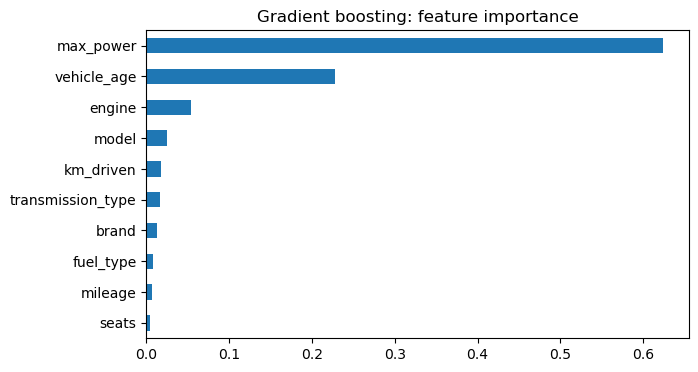

In [4]:
gb_names = best_gb.named_steps['prep'].get_feature_names_out()
gb_imp = pd.Series(best_gb.named_steps['gb'].feature_importances_, index=gb_names)
gb_grouped = gb_imp.groupby([original_feature(n) for n in gb_names]).sum().sort_values(ascending=False)
print(gb_grouped.round(3))

gb_grouped.head(10).sort_values().plot(kind='barh', figsize=(7, 4), title='Gradient boosting: feature importance')
plt.show()

## 4. Error by price segment and brand

In [5]:
print_segments(pred_gb)

segment
Q1 cheapest    0.171
Q2             0.117
Q3             0.103
Q4 priciest    0.115
Name: pct_error, dtype: float64
               size   mean
brand                     
Audi             33  0.127
BMW              78  0.135
Jaguar           14  0.192
Land Rover       11  0.261
Mercedes-Benz    58  0.157


## Results and takeaways

| Model | CV RMSE | Test RMSE | R² | MAE |
|---|---|---|---|---|
| Gradient boosting (600 trees, lr 0.1, depth 5, min leaf 5) | 0.1667 | 0.1679 | 0.9382 | ₹89,117 |

**Headline results**
- **Gradient boosting is the best model so far on every headline metric.** It beats the random forest by about 0.007 in test RMSE and about 0.005 in R², and it has the lowest rupee MAE of any model.
- **CV and test RMSE are close,** so the tuning didn't overfit the test set.
- **The best settings sit at the edge of the grid.** The best number of trees (600) and learning rate (0.1) are the largest values tested, so the model may improve with more trees or a higher learning rate. Widen the grid before treating these numbers as final.

**Feature importances**
- **Max power (0.62) and vehicle age (0.23) dominate,** the same pattern as the tree, forest, and Ridge.
- **Engine size (0.05) comes next.** The other features contribute little.

**Price segments**

| Segment | Gradient boosting | Random forest | KNN |
|---|---|---|---|
| Q1 cheapest | 17.1% | 18.1% | 19.8% |
| Q2 | 11.7% | 12.0% | 12.8% |
| Q3 | 10.3% | 10.2% | 10.9% |
| Q4 priciest | 11.5% | 11.9% | 12.1% |

Boosting has the lowest error in three of the four quartiles. In Q3 it's slightly behind the forest (10.3% vs 10.2%).

**Luxury brands**

| Brand | Gradient boosting | Random forest | KNN |
|---|---|---|---|
| Audi | 12.7% | 13.4% | 13.5% |
| BMW | 13.5% | 13.9% | 13.0% |
| Jaguar | 19.2% | 17.0% | 17.9% |
| Land Rover | 26.1% | 23.1% | 20.5% |
| Mercedes-Benz | 15.7% | 15.9% | 17.8% |

- Boosting is the best of the three on Audi and Mercedes-Benz, and it's second on BMW. It's the weakest on Jaguar and Land Rover.
- Jaguar has 14 test cars and Land Rover has 11, so those two results are noisy. Don't draw strong conclusions from them alone.